## Labels vs. Scale: Breaking Even on Banking77 with Encoders and Decoders

#### Results

This notebook only **displays** results. All logic lives in `scripts/evaluation.py`, which every model script also uses, so the files are written, checked and scored the same way everywhere.

Every model run writes one prediction CSV per split to `results/`, following `results/PREDICTION_FORMAT.md`. A file that breaks the format stops the scoring with a list of every problem found.

**Ground rules**
- Tune on `val`, report on `test`.
- An unmatched decoder answer (`-1`) counts as wrong. It is never dropped.

#### Setup

In [12]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd

# Find the project root (the folder that contains scripts/download_data.py), wherever the kernel starts
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "scripts" / "download_data.py").exists()), cwd)

# Make scripts/ importable, then load the shared evaluation module

sys.path.insert(0, str(ROOT / "scripts"))
import evaluation as ev

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

print("Prediction files in results/:", len(list(ev.RESULTS.glob("*.csv"))))

def natural_order(summary):
    # For display only: sort by model, then by budget size (k1, k3, ..., full) instead of alphabetically
    order = [b for b in ev.BUDGETS if b in summary["budget"].unique()]
    out = summary.copy()
    out["budget"] = pd.Categorical(out["budget"], categories=order, ordered=True)
    return out.sort_values(["model", "budget"]).reset_index(drop=True)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Prediction files in results/: 96


#### Validation scores
The same scoring on the validation split. Use these to tune, and use the test scores above only for the final numbers.

In [13]:
val_summary = ev.summarize(ev.score_all("val"))
natural_order(val_summary).round(3)

,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
0,majority,baseline,k1,0.013,0.000,0.000,0.000,3
1,majority,baseline,k3,0.013,0.000,0.000,0.000,3
2,majority,baseline,k5,0.013,0.000,0.000,0.000,3
3,majority,baseline,k10,0.013,0.000,0.000,0.000,3
4,majority,baseline,k20,0.013,0.000,0.000,0.000,3
5,majority,baseline,k30,0.013,0.000,0.000,0.000,3
6,majority,baseline,p50,0.013,0.000,0.000,0.000,3
7,majority,baseline,full,0.013,0.000,0.000,0.000,3
8,tfidf_lr,baseline,k1,0.284,0.004,0.265,0.003,3
9,tfidf_lr,baseline,k3,0.483,0.018,0.461,0.016,3


#### Score every run
`score_all` loads each `*_test.csv`, checks it against the format, and scores it. `summarize` then gives the mean and standard deviation across seeds for each model and budget.

In [14]:
# One row per run, then mean and standard deviation across seeds
scores = ev.score_all("test")
summary = ev.summarize(scores)
natural_order(summary).round(3)

,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
0,majority,baseline,k1,0.013,0.000,0.000,0.000,3
1,majority,baseline,k3,0.013,0.000,0.000,0.000,3
2,majority,baseline,k5,0.013,0.000,0.000,0.000,3
3,majority,baseline,k10,0.013,0.000,0.000,0.000,3
4,majority,baseline,k20,0.013,0.000,0.000,0.000,3
5,majority,baseline,k30,0.013,0.000,0.000,0.000,3
6,majority,baseline,p50,0.013,0.000,0.000,0.000,3
7,majority,baseline,full,0.013,0.000,0.000,0.000,3
8,tfidf_lr,baseline,k1,0.284,0.028,0.271,0.031,3
9,tfidf_lr,baseline,k3,0.484,0.012,0.473,0.012,3


### Are all runs there?
Seeds found for each model and budget. A missing run shows as `NaN`; zero-shot models should have exactly 1 seed.

In [4]:
# Columns in budget order, only the budgets that exist
order = [b for b in ev.BUDGETS if b in summary["budget"].unique()]
summary.pivot(index="model", columns="budget", values="n_seeds")[order]

budget,k1,k3,k5,k10,k20,k30,p50,full
model,,,,,,,,
majority,3,3,3,3,3,3,3,3
tfidf_lr,3,3,3,3,3,3,3,3


#### Learning curves
Score against the number of training examples (log scale). Where the encoder and decoder lines cross is the break-even point. The shaded band is one standard deviation across seeds. Zero-shot models are flat dashed lines. The figures are also saved to `reports/figures/`.

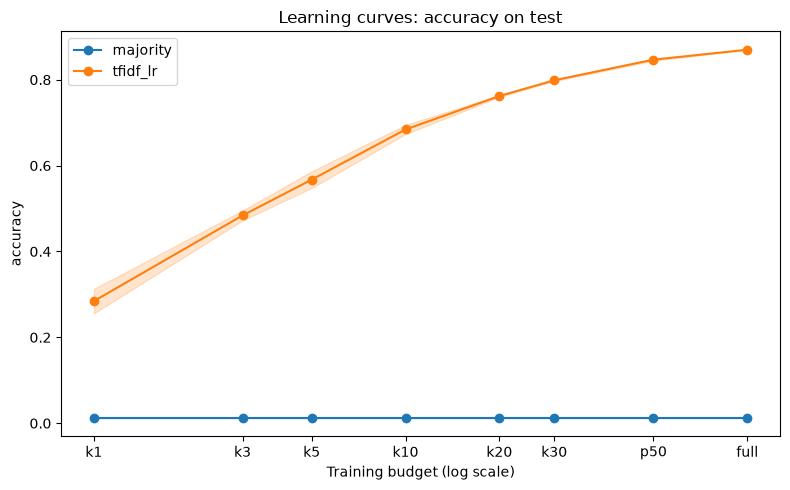

In [5]:
# Accuracy (primary metric)
ev.plot_learning_curve(summary, "accuracy", save_to=FIG / "learning_curve_accuracy.png")

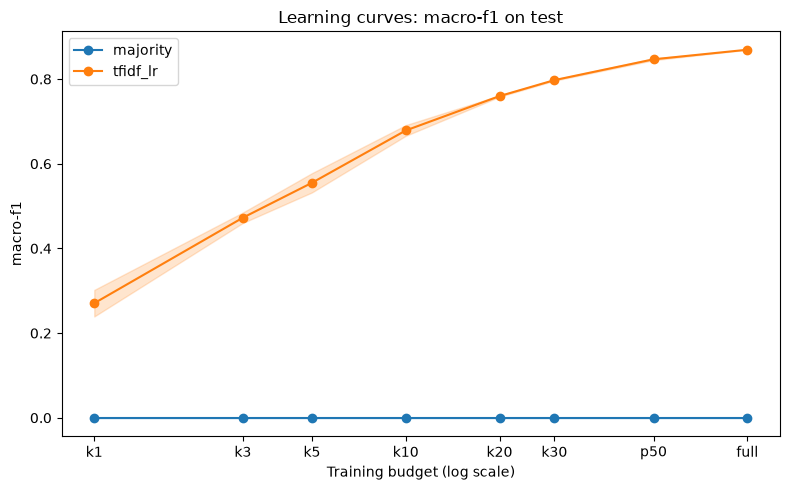

In [6]:
# Macro-F1 (secondary metric)
ev.plot_learning_curve(summary, "macro_f1", save_to=FIG / "learning_curve_macro_f1.png")

#### Look inside one run
Change `RUN` to any file in `results/`. The first table shows the ten weakest intents. The second shows the most frequent mistakes (an unmatched decoder answer appears as `unmatched`).

In [8]:
# Any prediction file in results/

# RUN = "majority_full_seed0_test.csv"
RUN = "tfidf_lr_full_seed0_test.csv"

df = ev.load_predictions(ev.RESULTS / RUN)
print("Run:", RUN)
print("Scores:", ev.score(df))

# The ten intents with the lowest F1
ev.per_intent(df).sort_values("f1").head(10)

Run: tfidf_lr_full_seed0_test.csv
Scores: {'accuracy': 0.8698051948051948, 'macro_f1': 0.8692678224375207}


,intent,precision,recall,f1,support
72,virtual_card_not_working,1.000000,0.325,0.490566,40
5,balance_not_updated_after_bank_transfer,0.620000,0.775,0.688889,40
37,get_disposable_virtual_card,0.673913,0.775,0.720930,40
14,card_not_working,0.625000,0.875,0.729167,40
16,card_payment_not_recognised,0.680851,0.800,0.735632,40
74,why_verify_identity,0.777778,0.700,0.736842,40
69,verify_my_identity,0.695652,0.800,0.744186,40
48,pending_transfer,0.800000,0.700,0.746667,40
61,top_up_reverted,0.775000,0.775,0.775000,40
34,extra_charge_on_statement,0.723404,0.850,0.781609,40


In [9]:
# The ten most frequent mistakes: true intent -> predicted intent
ev.top_confusions(df, 10)

,true,predicted,count
0,virtual_card_not_working,get_disposable_virtual_card,13
1,why_verify_identity,verify_my_identity,9
2,virtual_card_not_working,getting_virtual_card,6
3,card_acceptance,card_not_working,6
4,card_swallowed,declined_cash_withdrawal,6
5,top_up_reverted,top_up_failed,6
6,unable_to_verify_identity,verify_my_identity,5
7,request_refund,Refund_not_showing_up,5
8,transfer_timing,balance_not_updated_after_bank_transfer,4
9,fiat_currency_support,exchange_via_app,4
